# Grid-cell leakage and CCI/C3S download

Repeats the leakage analysis in each of the 805 OISST cells, then downloads the ESA CCI/C3S SST analysis from the Copernicus Marine Service and averages it over the study box (cells V1-0, V1-1). A Copernicus Marine account is needed for the download.

**Thesis:** Sections 3.12, 3.13, 4.3.2 · Table 4.3 · Figs. 4.7, 4.8 · Appendix C.9, C.10  
**Input:** oisst_box_grid.nc (OISST cut to the box)  
**Output:** wp1c_grid_leakage_*.csv, cci_sst/cci_box_YYYY.csv

Runs on Google Colab with the folder layout described in the repository README (`/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/...`). The printed outputs below are from the original run used in the thesis.

WP1c-1  gridded leakage: setup, detection on every ocean cell (self-contained; ~3-6 min)

In [2]:
import os, shutil
from google.colab import drive

mp = '/content/drive'
if os.path.ismount(mp):
    print('Drive is already mounted.')
else:
    files = [os.path.join(r, f) for r, _, fs in os.walk(mp) for f in fs]
    if files:
        print('STOP: files found in the local folder, not deleting:', files[:10])
    else:
        shutil.rmtree(mp, ignore_errors=True)          # only empty local folders created by WP1c-1
        drive.mount(mp)

p = '/content/drive/MyDrive/MHW/mhw_check/oisst_box_grid.nc'
print('file exists:', os.path.exists(p))

Mounted at /content/drive
file exists: True


In [3]:
# ================= WP1c-1  gridded leakage: setup, detection on every ocean cell (self-contained; ~3-6 min) =================
import os, glob, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
PROC = os.environ.get('PROC', '/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/processed')
ROOT = os.environ.get('ROOT', '/content/drive/MyDrive')
FIG  = f'{PROC}/figures'; os.makedirs(FIG, exist_ok=True)
LEADS = [1, 2, 3, 5, 7, 10, 14]
B = 2000

hits = glob.glob(f'{ROOT}/**/oisst_box_grid.nc', recursive=True); print(hits)
ds  = xr.open_dataset(hits[0])
ds  = ds.rename({k: v for k, v in {'latitude': 'lat', 'longitude': 'lon'}.items() if k in ds.dims})
sst = (ds['sst'] if 'sst' in ds else ds[list(ds.data_vars)[0]]).squeeze(drop=True)
sst = sst.sel(time=slice('1982-01-01', '2025-12-31')).sortby('lat').load()
A   = sst.values.astype('float64')                                   # time x lat x lon
T   = pd.DatetimeIndex(sst.time.values)
ocean = np.isfinite(A).all(0)
X   = A[:, ocean]                                                    # time x cells
LAT, LON = np.meshgrid(sst.lat.values, sst.lon.values, indexing='ij')
clat, clon = LAT[ocean], LON[ocean]
tc  = np.arange(len(T)) - (len(T) - 1) / 2
slope = (X * tc[:, None]).sum(0) / (tc ** 2).sum()                   # per-cell linear trend (per day)
Xd  = X - slope[None, :] * tc[:, None]                               # detrended, same form as the box mean
print(f'{X.shape[0]} days x {X.shape[1]} ocean cells | cell trends {np.percentile(slope*3652.5, 10):.2f} to '
      f'{np.percentile(slope*3652.5, 90):.2f} degC/decade (10th-90th pct)')

def doy366(idx):
    d = idx.dayofyear.values.copy(); d[(~idx.is_leap_year) & (idx.month > 2)] += 1
    return d

def hobday_thr(M, T, base=(1982, 2021), win=5, smooth=31, pct=90):
    """Hobday et al. (2016) 90th-percentile threshold for every column of M (time x cells), as in WP1."""
    d, inb = doy366(T), (T.year >= base[0]) & (T.year <= base[1])
    c = np.full((367, M.shape[1]), np.nan)
    for k in range(1, 367):
        if k == 60: continue
        idx  = np.where((d == k) & inb)[0]
        pool = np.unique(np.clip((idx[:, None] + np.arange(-win, win + 1)).ravel(), 0, len(T) - 1))
        c[k] = np.nanpercentile(M[pool[inb[pool]]], pct, axis=0)
    c[60] = (c[59] + c[61]) / 2
    c = c[1:]; h = smooth // 2
    c = np.concatenate([c[-h:], c, c[:h]])
    cs = np.cumsum(np.vstack([np.zeros((1, c.shape[1])), c]), axis=0)
    c = (cs[smooth:] - cs[:-smooth]) / smooth                           # 31-day running mean, wrapped
    return c[d - 1]

def detect_cols(E, min_dur=5, max_gap=2):
    """Per column: causal (knowable on day t), nojoin (min-duration only), label (full Hobday)."""
    causal = np.zeros(E.shape, np.int8); nojoin = np.zeros(E.shape, np.int8); label = np.zeros(E.shape, np.int8)
    for j in range(E.shape[1]):
        b = np.diff(np.r_[0, E[:, j].astype(np.int8), 0])
        st, en = np.where(b == 1)[0], np.where(b == -1)[0] - 1
        keep = en - st + 1 >= min_dur; st, en = st[keep], en[keep]
        for s, e in zip(st, en):
            nojoin[s:e + 1, j] = 1; causal[s + min_dur - 1:e + 1, j] = 1
        label[:, j] = nojoin[:, j]
        for k in range(len(st) - 1):
            if st[k + 1] - en[k] - 1 <= max_gap: label[en[k] + 1:st[k + 1], j] = 1
    return causal, nojoin, label

# verification: the grid code applied to the box-mean series must reproduce your label file
df = pd.read_csv(f'{PROC}/predictor_table_1982_2025.csv', index_col=0, parse_dates=True)
for kind, s_col, t_col, l_col in (('raw', 'sst', 'thresh90', 'mhw_raw'), ('det', 'sst_detrended', 'thresh90_detrended', 'mhw_detrended')):
    th = hobday_thr(df[[s_col]].values, df.index)
    _, _, lab = detect_cols(df[[s_col]].values > th)
    print(f'check {kind}: max threshold diff {np.abs(th[:, 0] - df[t_col].values).max():.4f} degC | '
          f'mismatched label days {int((lab[:, 0] != df[l_col].values).sum())}')

LAB = {}
for kind, M in (('det', Xd), ('raw', X)):
    th = hobday_thr(M, T)
    exc = M > th
    c, nj, lab = detect_cols(exc)
    LAB[kind] = dict(exc=exc.astype(np.int8), causal=c, nojoin=nj, label=lab)
    print(f'{kind}: median MHW days per cell {int(np.median(lab.sum(0)))}, '
          f'median hindsight share {np.median(((lab == 1) & (c == 0)).sum(0) / lab.sum(0)):.1%}')

['/content/drive/MyDrive/MHW/mhw_check/oisst_box_grid.nc']
16071 days x 805 ocean cells | cell trends 0.18 to 0.24 degC/decade (10th-90th pct)
check raw: max threshold diff 0.0001 degC | mismatched label days 0
check det: max threshold diff 0.0003 degC | mismatched label days 0
det: median MHW days per cell 1009, median hindsight share 45.7%
raw: median MHW days per cell 1357, median hindsight share 39.1%


WP1c-2  leakage per cell, by lead, with year-block bootstrap

In [4]:
# ================= WP1c-2  leakage per cell, by lead, with year-block bootstrap =================
def mcc(tp, fp, fn, tn):
    tp, fp, fn, tn = (np.asarray(v, float) for v in (tp, fp, fn, tn))
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return np.where(den > 0, (tp * tn - fp * fn) / np.where(den > 0, den, 1), 0.0)

yrs = np.unique(T.year)
rng = np.random.default_rng(0); idx = rng.integers(0, len(yrs), (B, len(yrs)))

def year_counts(p, y, tyear):
    """Contingency counts per target year and cell -> array (4, years, cells)."""
    starts = np.r_[0, np.where(np.diff(tyear) != 0)[0] + 1]
    out = []
    for a in ((p == 1) & (y == 1), (p == 1) & (y == 0), (p == 0) & (y == 1), (p == 0) & (y == 0)):
        out.append(np.add.reduceat(a.astype(np.int32), starts, axis=0))
    return np.stack(out)

def boot_mcc(c, chunk=250):
    """Year-block bootstrap MCC per cell, in chunks to keep memory low."""
    return np.vstack([mcc(*c[:, idx[k:k + chunk]].sum(2)) for k in range(0, B, chunk)])

rows, CELL = [], {}
box = pd.read_csv(f'{PROC}/wp1_leakage_curve_bob.csv')
for kind in ('det', 'raw'):
    L = LAB[kind]
    hind = ((L['label'] == 1) & (L['causal'] == 0)).sum(0) / L['label'].sum(0)
    for h in LEADS:
        y = L['label'][h:]; tyear = T.year.values[h:]
        cnt = {n: year_counts(L[n][:-h], y, tyear) for n in ('label', 'nojoin', 'causal', 'exc')}
        pt  = {n: mcc(*c.sum(1)) for n, c in cnt.items()}                       # point MCC per cell
        bt  = {n: boot_mcc(c) for n, c in cnt.items() if n in ('label', 'causal')}              # B x cells
        d   = bt['label'] - bt['causal']
        lo, hi = np.percentile(d, 2.5, 0), np.percentile(d, 97.5, 0)
        infl = pt['label'] - pt['causal']
        CELL[(kind, h)] = dict(infl=infl, lo=lo, hi=hi, gap_exc=pt['exc'] - pt['causal'], hind=hind,
                               mcc_label=pt['label'], mcc_causal=pt['causal'])
        bm = box[(box.target == kind) & (box.lead == h)].inflation_total.values[0]
        rows.append({'labels': kind, 'lead': h, 'box-mean inflation': round(bm, 3),
                     'cell inflation median': round(float(np.median(infl)), 3),
                     'cell inflation 10th-90th pct': f'{np.percentile(infl, 10):.3f} to {np.percentile(infl, 90):.3f}',
                     'cells with CI > 0 (%)': round(100 * float(np.mean(lo > 0)), 1),
                     'cells where cell > box (%)': round(100 * float(np.mean(infl > bm)), 1),
                     'share from 5-day minimum (median)': round(float(np.median((pt['nojoin'] - pt['causal']) / np.where(infl != 0, infl, np.nan))), 2),
                     'exceedance minus honest (median)': round(float(np.median(pt['exc'] - pt['causal'])), 3)})
GR = pd.DataFrame(rows); GR.to_csv(f'{PROC}/wp1c_grid_leakage_summary.csv', index=False)
pd.DataFrame({'lat': clat, 'lon': clon, **{f'{k}_{h}_{v}': CELL[(k, h)][v] for (k, h) in CELL for v in ('infl', 'lo', 'hi', 'gap_exc')},
              'hind_det': CELL[('det', 1)]['hind'], 'hind_raw': CELL[('raw', 1)]['hind']}).to_csv(f'{PROC}/wp1c_grid_leakage_cells.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
print(GR.to_string(index=False))
for kind in ('det', 'raw'):
    c1 = CELL[(kind, 1)]
    r = pd.Series(c1['hind']).corr(pd.Series(c1['infl']), method='spearman')
    print(f'{kind}: Spearman r across cells, hindsight share vs 1-day inflation = {r:.2f} (descriptive; cells are spatially correlated)')
print('RULE (detrended): grid-scale leakage holds if >= 90% of cells have CI > 0 at every lead 1-7 d ->',
      'MET' if all(GR[(GR.labels == 'det') & (GR.lead <= 7)]['cells with CI > 0 (%)'] >= 90) else 'NOT MET')

labels  lead  box-mean inflation  cell inflation median cell inflation 10th-90th pct  cells with CI > 0 (%)  cells where cell > box (%)  share from 5-day minimum (median)  exceedance minus honest (median)
   det     1               0.277                  0.311               0.284 to 0.342                  100.0                        95.9                               0.98                             0.109
   det     2               0.285                  0.316               0.286 to 0.348                  100.0                        90.8                               0.98                             0.139
   det     3               0.266                  0.294               0.265 to 0.328                  100.0                        89.3                               0.98                             0.147
   det     5               0.186                  0.197               0.174 to 0.228                  100.0                        70.6                               0.96          

WP1c-3  figures: maps + cell distribution vs box mean

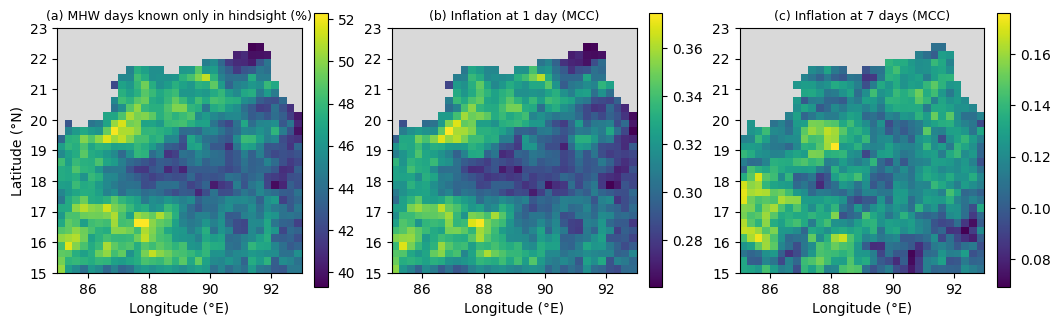

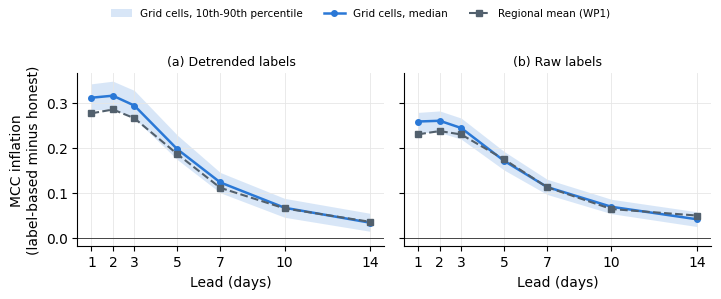

In [5]:
# ================= WP1c-3  figures: maps + cell distribution vs box mean =================
def to_map(v):
    m = np.full(ocean.shape, np.nan); m[ocean] = v; return m
cm = plt.get_cmap('viridis').copy(); cm.set_bad('0.85')
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.4), constrained_layout=True)
panels = [(100 * CELL[('det', 1)]['hind'], '(a) MHW days known only in hindsight (%)', None),
          (CELL[('det', 1)]['infl'], '(b) Inflation at 1 day (MCC)', CELL[('det', 1)]['lo']),
          (CELL[('det', 7)]['infl'], '(c) Inflation at 7 days (MCC)', CELL[('det', 7)]['lo'])]
for ax, (v, ttl, lo) in zip(axs, panels):
    pc = ax.pcolormesh(sst.lon, sst.lat, np.ma.masked_invalid(to_map(v)), cmap=cm, shading='nearest')
    if lo is not None:
        ns = lo <= 0
        ax.plot(clon[ns], clat[ns], 'k.', ms=1.5)
    fig.colorbar(pc, ax=ax, shrink=0.85)
    ax.set_title(ttl, fontsize=9); ax.set_aspect('equal'); ax.set_xlabel('Longitude (°E)')
axs[0].set_ylabel('Latitude (°N)')
fig.savefig(f'{FIG}/wp1c_grid_leakage_maps.png', dpi=300)

fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.0), sharey=True)
for ax, kind, ttl in zip(axs, ('det', 'raw'), ('(a) Detrended labels', '(b) Raw labels')):
    med = [np.median(CELL[(kind, h)]['infl']) for h in LEADS]
    p10 = [np.percentile(CELL[(kind, h)]['infl'], 10) for h in LEADS]
    p90 = [np.percentile(CELL[(kind, h)]['infl'], 90) for h in LEADS]
    bm  = [box[(box.target == kind) & (box.lead == h)].inflation_total.values[0] for h in LEADS]
    ax.fill_between(LEADS, p10, p90, color='#2a78d6', alpha=0.18, lw=0, label='Grid cells, 10th-90th percentile')
    ax.plot(LEADS, med, 'o-', color='#2a78d6', lw=1.8, ms=4, label='Grid cells, median')
    ax.plot(LEADS, bm, 's--', color='#52606d', lw=1.5, ms=4, label='Regional mean (WP1)')
    ax.axhline(0, color='#444', lw=0.7); ax.set_xticks(LEADS); ax.set_xlabel('Lead (days)'); ax.set_title(ttl, fontsize=9)
    ax.grid(color='#e6e6e6', lw=0.6); [ax.spines[s].set_visible(False) for s in ('top', 'right')]
axs[0].set_ylabel('MCC inflation\n(label-based minus honest)')
h_, l_ = axs[0].get_legend_handles_labels(); fig.legend(h_, l_, loc='upper center', ncol=3, fontsize=7.5, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.88)); fig.savefig(f'{FIG}/wp1c_grid_vs_box.png', dpi=300)
plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 68.2 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


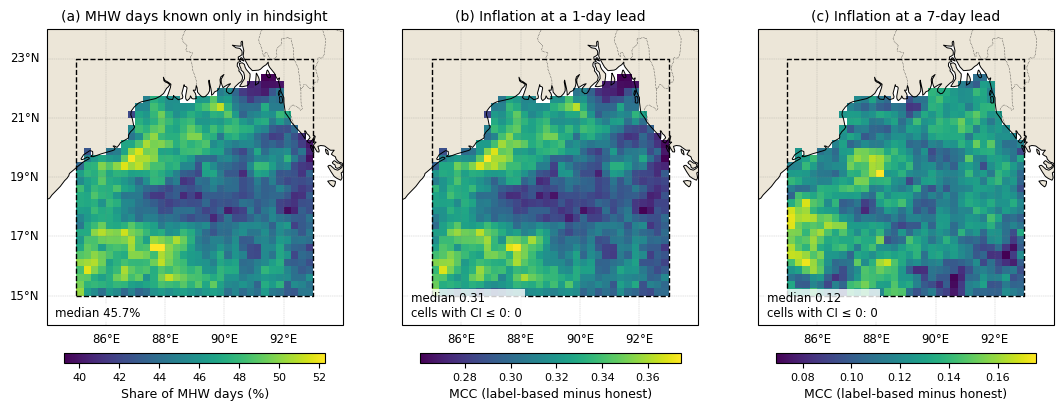

In [6]:
# ===== WP1c-3b  grid-leakage maps with Cartopy (PlateCarree) =====
!pip -q install cartopy
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mticker
import cartopy.crs as ccrs, cartopy.feature as cfeature

PROC = '/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/processed'
FIG  = f'{PROC}/figures'
C    = pd.read_csv(f'{PROC}/wp1c_grid_leakage_cells.csv')
lats, lons = np.sort(C.lat.unique()), np.sort(C.lon.unique())
grid = lambda col, k=1: (C.pivot_table(index='lat', columns='lon', values=col)
                          .reindex(index=lats, columns=lons).values * k)

panels = [('hind_det',   100, '(a) MHW days known only in hindsight', 'Share of MHW days (%)', None),
          ('det_1_infl', 1,   '(b) Inflation at a 1-day lead',        'MCC (label-based minus honest)', 'det_1_lo'),
          ('det_7_infl', 1,   '(c) Inflation at a 7-day lead',        'MCC (label-based minus honest)', 'det_7_lo')]
pc_ = ccrs.PlateCarree()
fig = plt.figure(figsize=(13, 5.2))
for i, (col, k, title, cblab, locol) in enumerate(panels):
    ax = fig.add_subplot(1, 3, i + 1, projection=pc_)
    ax.set_extent([84, 94, 14, 24], crs=pc_)
    ax.add_feature(cfeature.LAND.with_scale('50m'), facecolor='#ece6d8', zorder=1)
    Z = np.ma.masked_invalid(grid(col, k))
    pm = ax.pcolormesh(lons, lats, Z, cmap='viridis', shading='nearest', transform=pc_, zorder=2)
    ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=0.7, zorder=3)
    ax.add_feature(cfeature.BORDERS.with_scale('50m'), linewidth=0.4, linestyle=':', zorder=3)
    ax.plot([85, 93, 93, 85, 85], [15, 15, 23, 23, 15], 'k--', lw=1, transform=pc_, zorder=4)
    if locol is not None:                                   # cells whose 95% CI includes zero
        ns = C[locol] <= 0
        ax.scatter(C.lon[ns], C.lat[ns], s=3, c='k', transform=pc_, zorder=5)
        note = f'median {np.nanmedian(C[col]):.2f}\ncells with CI ≤ 0: {int(ns.sum())}'
    else:
        note = f'median {np.nanmedian(C[col] * k):.1f}%'
    ax.text(84.3, 14.3, note, fontsize=8.5, transform=pc_, zorder=6,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=2))
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = gl.right_labels = False
    gl.left_labels = (i == 0)
    gl.xlocator = mticker.FixedLocator([86, 88, 90, 92]); gl.ylocator = mticker.FixedLocator([15, 17, 19, 21, 23])
    gl.xlabel_style = gl.ylabel_style = {'size': 8.5}
    ax.set_title(title, fontsize=10)
    cb = fig.colorbar(pm, ax=ax, orientation='horizontal', pad=0.07, shrink=0.88, aspect=28)
    cb.set_label(cblab, fontsize=9); cb.ax.tick_params(labelsize=8)
fig.savefig(f'{FIG}/wp1c_grid_leakage_maps.png', dpi=300, bbox_inches='tight')
plt.show()

# CDS Marine


In [ ]:
# ===== V1-0  Copernicus Marine login + list the datasets in the CCI/C3S product =====
!pip -q install copernicusmarine
import copernicusmarine
copernicusmarine.login()                         # enter your Copernicus Marine username and password
info = copernicusmarine.describe(product_id='SST_GLO_SST_L4_REP_OBSERVATIONS_010_024')
IDS = [d.dataset_id for p in info.products for d in p.datasets]
print(IDS)
import xarray as xr; print('zarr' in xr.backends.list_engines())

In [ ]:
# ===== V1-1  CCI/C3S daily SST -> study-box mean, 1982-2024 (resumable; nc files deleted after use) =====
import os, numpy as np, pandas as pd, xarray as xr
PROC = '/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/processed'
OUTD = f'{PROC}/cci_sst'; os.makedirs(OUTD, exist_ok=True)
TMP  = '/content/cci_tmp'; os.makedirs(TMP, exist_ok=True)
for yr in range(1982, 2025):
    out = f'{OUTD}/cci_box_{yr}.csv'
    if os.path.exists(out): continue
    f = None
    for ds_id in IDS:
        try:
            copernicusmarine.subset(dataset_id=ds_id, variables=['analysed_sst'],
                                    minimum_longitude=85, maximum_longitude=93, minimum_latitude=15, maximum_latitude=23,
                                    start_datetime=f'{yr}-01-01T00:00:00', end_datetime=f'{yr}-12-31T23:59:59',
                                    output_directory=TMP, output_filename=f'cci_{yr}.nc', overwrite=True)
            f = f'{TMP}/cci_{yr}.nc'; break
        except Exception as e:
            print(yr, ds_id, 'not available:', str(e)[:100])
    if f is None: raise RuntimeError(f'{yr}: no dataset in {IDS} covers this year')
    with xr.open_dataset(f) as ds:
        v = ds['analysed_sst'].squeeze(drop=True).load()
    if float(v.mean()) > 200: v = v - 273.15                      # Kelvin -> degC
    lat = 'latitude' if 'latitude' in v.dims else 'lat'; lon = 'longitude' if 'longitude' in v.dims else 'lon'
    ocean = np.isfinite(v).all('time')
    w = np.cos(np.deg2rad(v[lat])) * ocean
    s = ((v.where(ocean) * w).sum((lat, lon)) / w.sum()).to_series()
    s.index = pd.to_datetime(s.index).normalize()
    pd.DataFrame({'sst': s, 'ocean_cells': int(ocean.sum())}).to_csv(out)
    os.remove(f); print(yr, len(s), 'days |', int(ocean.sum()), 'ocean cells')